# METAMER-SAE — Notebook 07
## Overcomplete TopK Feature Analysis

**Project:** `metamer-sae`  
**Notebook:** `07_topk_feature_analysis.ipynb`  
**Purpose:** Inspect the selected natural-image-trained TopK SAE, characterize its features, assess seed stability, and explore feature responses to the eight Feather development triplets.

### Scientific question

Do sparse features learned from natural-image observer activations reveal structured differences between natural photographs and model metamers generated by standard-trained and adversarially trained visual networks?

This notebook supports the original Project 08 motivation — *Which features make a model blind to what we see?* — through feature-pattern analysis. It does not replace the main paired representation-comparison strand.

### Scope and safeguards

- Primary SAE: extended 4× K64, seed 123, best epoch 125.
- Robustness replicate: extended 4× K64, seed 42, best epoch 123.
- Input: pooled 384-D ConvNeXt-Tiny Stage 3 activations only.
- Preprocessing: subtract the saved Imagenette-training activation mean; no standardisation or whitening.
- Natural-image galleries and activation statistics: Imagenette train and validation, kept distinct.
- Feather exploration: development triplets only (8 triplets / 24 images).
- Do not access the 32 primary evaluation or 8 reserve triplets.
- Do not fit or tune either SAE using Feather stimuli.
- No human behavioural data or recognisability analysis.
- This is a Colab prototype. The validated functions and data contracts will later be moved into the full `metamer-sae` codebase.

## 0. Runtime and project setup

This notebook assumes the existing Google Drive project and artifacts are available. It does not download datasets, regenerate activations, or train an SAE.

In [ ]:
from pathlib import Path
import os, sys, json, math, warnings, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
import torch.nn.functional as F

SEED = 123
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Platform:", platform.platform())

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
CUDA available: True
Platform: Linux-6.6.159+-x86_64-with-glibc2.35


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

PROJECT_ROOT = Path('/content/gdrive/MyDrive/metamer-sae')
assert PROJECT_ROOT.exists(), f"Project root not found: {PROJECT_ROOT}"

OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'topk_feature_analysis'
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
GALLERY_DIR = OUTPUT_DIR / 'feature_galleries'
for p in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, GALLERY_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Notebook 07 outputs:", OUTPUT_DIR)

Mounted at /content/gdrive
Project root: /content/gdrive/MyDrive/metamer-sae
Notebook 07 outputs: /content/gdrive/MyDrive/metamer-sae/outputs/topk_feature_analysis


## 1. Resolve the selected checkpoints and configuration

The selection manifest is authoritative. We read it first and resolve the primary and replicate checkpoints from the recorded paths. We do not substitute another run or overwrite Notebook 06 artifacts.

In [ ]:
SELECTION_PATH = PROJECT_ROOT / 'outputs/topk_sae/selected_sae_checkpoint.json'
assert SELECTION_PATH.exists(), f"Missing selection manifest: {SELECTION_PATH}"

with open(SELECTION_PATH, 'r') as f:
    selection_manifest = json.load(f)

print(json.dumps(selection_manifest, indent=2)[:12000])

{
  "project": "Metamer-SAE",
  "selection_timestamp_utc": "2026-11-19T16:54:19.906690+00:00",
  "selection_status": "provisional_validation_based_selection",
  "selected_configuration": {
    "expansion_factor": 4,
    "dictionary_size": 1536,
    "top_k": 64
  },
  "selected_run_id": "topk_4x_k64_seed123",
  "selected_stage": "200_epoch_replay_and_extend",
  "selected_seed": 123,
  "selected_best_epoch": 125,
  "selected_validation_mse": 0.0016301164756807836,
  "selected_validation_active_features": 1239,
  "selected_checkpoint_path": "/content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt",
  "pca_validation_mse": 0.0037489,
  "improvement_vs_pca_percent": 56.51747244042829,
  "selection_rule": "Lowest directly verified validation reconstruction MSE among the original and extended 4x K64 seed 42 and seed 123 checkpoints. The other seed is retained as a robustness replicate.",
  "held_out_feather_data_used_for_selection": false
}


In [ ]:
def find_string_values(obj, key_hints=()):
    found = []
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, (str, int, float)) and any(h in str(k).lower() for h in key_hints):
                found.append((str(k), str(v)))
            else:
                found.extend(find_string_values(v, key_hints))
    elif isinstance(obj, list):
        for v in obj:
            found.extend(find_string_values(v, key_hints))
    return found

# The handover records these exact relative locations. The manifest is checked first;
# these are used only as validated fallbacks if its schema stores a different key name.
PRIMARY_REL = 'outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt'
REPLICATE_REL = 'outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42/best_model.pt'

def resolve_checkpoint(manifest, expected_seed, fallback_rel):
    candidates = []
    for key, value in find_string_values(manifest, ('checkpoint', 'model_path', 'best_model', 'path')):
        if value.endswith('.pt'):
            candidates.append(value)
    # Prefer an explicit matching seed/path in the manifest.
    seed_text = str(expected_seed)
    matching = [v for v in candidates if seed_text in v and ('4x_k64' in v or 'convergence' in v)]
    candidate = matching[0] if matching else fallback_rel
    p = Path(candidate)
    if not p.is_absolute():
        p = PROJECT_ROOT / p
    if not p.exists():
        p = PROJECT_ROOT / fallback_rel
    assert p.exists(), f"Checkpoint for seed {expected_seed} not found: {p}"
    return p

PRIMARY_CKPT = resolve_checkpoint(selection_manifest, 123, PRIMARY_REL)
REPLICATE_CKPT = resolve_checkpoint(selection_manifest, 42, REPLICATE_REL)

print("Primary checkpoint:", PRIMARY_CKPT)
print("Replicate checkpoint:", REPLICATE_CKPT)

Primary checkpoint: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed123/best_model.pt
Replicate checkpoint: /content/gdrive/MyDrive/metamer-sae/outputs/topk_sae/convergence_200ep/topk_4x_k64_seed42/best_model.pt


## 2. Load both frozen TopK SAEs safely

The package version and constructor are the ones validated in Notebook 05/06. Checkpoints are loaded with `weights_only=True` and the `TorchVersion` safe-global allowlist; unrestricted pickle loading is deliberately not used.

We reconstruct the known 384 → 1,536 architecture with TopK=64 and load the state dictionaries strictly.

In [ ]:
# ============================================================
# METAMER-SAE — OVERCOMPLETE ENVIRONMENT SETUP
# Compatible with the Notebook 06 validated environment
# ============================================================

import sys

print("Python version:", sys.version)

# Overcomplete 0.3.0 requires Python < 3.13
assert sys.version_info < (3, 13), (
    f"Incompatible Python version: {sys.version}. "
    "Please select Colab Runtime Version 2026.07."
)

# Install the exact package version used in Notebook 06
%pip install --no-deps --no-cache-dir "overcomplete==0.3.0"

print("\nOvercomplete installation command completed.")

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 45.4 MB/s eta 0:00:00

Overcomplete installation command completed.


In [ ]:
import overcomplete
from importlib.metadata import version

OVERCOMPLETE_VERSION = version("overcomplete")

print("Overcomplete version:", OVERCOMPLETE_VERSION)

assert OVERCOMPLETE_VERSION == "0.3.0", (
    f"Expected 0.3.0, found {OVERCOMPLETE_VERSION}"
)

from overcomplete.sae import TopKSAE

print("TopKSAE import successful.")

Overcomplete version: 0.3.0
TopKSAE import successful.


In [ ]:
import importlib.metadata as importlib_metadata
try:
    overcomplete_version = importlib_metadata.version('overcomplete')
except importlib_metadata.PackageNotFoundError:
    overcomplete_version = 'not-installed'
print("Overcomplete:", overcomplete_version)
assert overcomplete_version == '0.3.0', (
    f"Expected validated Overcomplete 0.3.0, found {overcomplete_version}. "
    "Stop and inspect the environment rather than silently changing APIs."
)

from overcomplete.sae import TopKSAE
from torch.torch_version import TorchVersion

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
INPUT_DIM, DICT_WIDTH, TOP_K = 384, 1536, 64

def safe_load_checkpoint(path):
    with torch.serialization.safe_globals([TorchVersion]):
        return torch.load(path, map_location='cpu', weights_only=True)

def build_and_load_sae(checkpoint_path):
    checkpoint = safe_load_checkpoint(checkpoint_path)
    model = TopKSAE(input_shape=INPUT_DIM, nb_concepts=DICT_WIDTH, top_k=TOP_K)
    state = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))
    missing, unexpected = model.load_state_dict(state, strict=True)
    assert not missing and not unexpected
    model.to(DEVICE)
    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    return model, checkpoint

primary_model, primary_checkpoint = build_and_load_sae(PRIMARY_CKPT)
replicate_model, replicate_checkpoint = build_and_load_sae(REPLICATE_CKPT)

print("Loaded both models on:", DEVICE)
print("Primary checkpoint keys:", list(primary_checkpoint.keys()))
print("Replicate checkpoint keys:", list(replicate_checkpoint.keys()))

Overcomplete: 0.3.0
Loaded both models on: cuda
Primary checkpoint keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']
Replicate checkpoint keys: ['model_state_dict', 'run_config', 'best_epoch', 'best_validation_mse']


In [ ]:
def checkpoint_summary(name, path, checkpoint):
    cfg_path = path.parent / 'run_config.json'
    summary_path = path.parent / 'run_summary.json'
    cfg = json.load(open(cfg_path)) if cfg_path.exists() else {}
    summary = json.load(open(summary_path)) if summary_path.exists() else {}
    return {
        'model': name,
        'checkpoint': str(path),
        'config_file_exists': cfg_path.exists(),
        'summary_file_exists': summary_path.exists(),
        'config': json.dumps(cfg, default=str)[:1000],
        'summary': json.dumps(summary, default=str)[:1000],
        'checkpoint_metadata_keys': ', '.join(checkpoint.keys())
    }

checkpoint_table = pd.DataFrame([
    checkpoint_summary('primary_seed123', PRIMARY_CKPT, primary_checkpoint),
    checkpoint_summary('replicate_seed42', REPLICATE_CKPT, replicate_checkpoint)
])
display(checkpoint_table[['model','checkpoint','config_file_exists','summary_file_exists','checkpoint_metadata_keys']])
checkpoint_table.to_csv(TABLE_DIR / 'checkpoint_provenance.csv', index=False)

,model,checkpoint,config_file_exists,summary_file_exists,checkpoint_metadata_keys
0,primary_seed123,/content/gdrive/MyDrive/metamer-sae/outputs/to...,True,True,"model_state_dict, run_config, best_epoch, best..."
1,replicate_seed42,/content/gdrive/MyDrive/metamer-sae/outputs/to...,True,True,"model_state_dict, run_config, best_epoch, best..."


## 3. Load the original activation data and preserve preprocessing

We use the exact Notebook 05 training activation mean. The model input is the original pooled 384-D activation minus that saved mean. No new centering statistics are estimated here.

The Feather activations are not used to fit or tune the dictionary.

In [ ]:
PREP_DIR = PROJECT_ROOT / 'outputs/sae_preparation'
MEAN_PATH = PREP_DIR / 'training_activation_mean.npy'
TRAIN_CENTERED_PATH = PREP_DIR / 'train_centered_activations.npy'
VAL_CENTERED_PATH = PREP_DIR / 'validation_centered_activations.npy'

for p in (MEAN_PATH, TRAIN_CENTERED_PATH, VAL_CENTERED_PATH):
    assert p.exists(), f"Required preparation artifact missing: {p}"

training_mean = np.load(MEAN_PATH).astype(np.float32)
X_train = np.load(TRAIN_CENTERED_PATH, mmap_mode='r')
X_val = np.load(VAL_CENTERED_PATH, mmap_mode='r')

assert training_mean.shape == (384,)
assert X_train.shape == (9469, 384)
assert X_val.shape == (3925, 384)
assert np.isfinite(training_mean).all()
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

print("Training mean:", training_mean.shape)
print("Centered train:", X_train.shape, X_train.dtype)
print("Centered validation:", X_val.shape, X_val.dtype)

Training mean: (384,)
Centered train: (9469, 384) float32
Centered validation: (3925, 384) float32


## 4. Validate model outputs and extract latent codes

For each input, Overcomplete returns pre-TopK activations, sparse TopK codes and reconstruction. We verify the API output shapes before running the full analysis.

The primary SAE is the main analysis model. The seed-42 model is used for cross-seed robustness only.

In [ ]:
with torch.no_grad():
    probe = torch.as_tensor(np.asarray(X_val[:8]), dtype=torch.float32, device=DEVICE)
    probe_pre, probe_codes, probe_recon = primary_model(probe)

print("Input:", tuple(probe.shape))
print("Pre-codes:", tuple(probe_pre.shape))
print("Sparse codes:", tuple(probe_codes.shape))
print("Reconstruction:", tuple(probe_recon.shape))

assert probe_pre.shape == (8, DICT_WIDTH)
assert probe_codes.shape == (8, DICT_WIDTH)
assert probe_recon.shape == (8, INPUT_DIM)
assert torch.isfinite(probe_codes).all()
assert torch.isfinite(probe_recon).all()
assert (probe_codes != 0).sum(dim=1).eq(TOP_K).all(), "TopK sparsity check failed"

/tmp/ipykernel_285/3385916289.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  probe = torch.as_tensor(np.asarray(X_val[:8]), dtype=torch.float32, device=DEVICE)


Input: (8, 384)
Pre-codes: (8, 1536)
Sparse codes: (8, 1536)
Reconstruction: (8, 384)


In [ ]:
def encode_array(model, X, batch_size=512, return_pre=False):
    codes_all, pre_all, recon_all = [], [], []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = torch.as_tensor(np.asarray(X[start:start+batch_size]),
                                 dtype=torch.float32, device=DEVICE)
            pre, codes, recon = model(xb)
            codes_all.append(codes.cpu().numpy())
            if return_pre:
                pre_all.append(pre.cpu().numpy())
            recon_all.append(recon.cpu().numpy())
    codes = np.concatenate(codes_all)
    pre = np.concatenate(pre_all) if return_pre else None
    recon = np.concatenate(recon_all)
    return codes, pre, recon

train_codes, train_pre, train_recon = encode_array(primary_model, X_train, return_pre=True)
val_codes, val_pre, val_recon = encode_array(primary_model, X_val, return_pre=True)

def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

natural_reconstruction = pd.DataFrame([
    {'split':'train','n':len(X_train),'mse':mse(X_train,train_recon)},
    {'split':'validation','n':len(X_val),'mse':mse(X_val,val_recon)}
])
display(natural_reconstruction)
natural_reconstruction.to_csv(TABLE_DIR / 'natural_reconstruction_metrics.csv', index=False)

np.save(OUTPUT_DIR / 'imagenette_train_sparse_codes_seed123.npy', train_codes)
np.save(OUTPUT_DIR / 'imagenette_validation_sparse_codes_seed123.npy', val_codes)

,split,n,mse
0,train,9469,0.000977
1,validation,3925,0.001630


## 5. Global feature-use statistics

For each feature, we calculate:
- active-example count and activation density;
- mean and maximum nonzero activation;
- mean activation including zeros;
- median and upper quantile of nonzero activations.

For TopK codes, each example should have exactly 64 nonzero entries. A feature with zero nonzero activations across the split is dead on that split. These are descriptive utilization statistics, not semantic labels.

In [ ]:
def feature_statistics(codes, split_name):
    codes = np.asarray(codes)
    active = codes != 0
    nonzero = np.where(active, codes, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        mean_nonzero = np.nanmean(nonzero, axis=0)
        median_nonzero = np.nanmedian(nonzero, axis=0)
        q95_nonzero = np.nanquantile(nonzero, 0.95, axis=0)
    mean_nonzero = np.nan_to_num(mean_nonzero, nan=0.0)
    median_nonzero = np.nan_to_num(median_nonzero, nan=0.0)
    q95_nonzero = np.nan_to_num(q95_nonzero, nan=0.0)
    return pd.DataFrame({
        'feature_id': np.arange(codes.shape[1]),
        'split': split_name,
        'active_count': active.sum(axis=0),
        'activation_density': active.mean(axis=0),
        'mean_activation_all_examples': codes.mean(axis=0),
        'mean_nonzero_activation': mean_nonzero,
        'median_nonzero_activation': median_nonzero,
        'q95_nonzero_activation': q95_nonzero,
        'max_activation': codes.max(axis=0)
    })

train_stats = feature_statistics(train_codes, 'train')
val_stats = feature_statistics(val_codes, 'validation')
feature_stats = pd.concat([train_stats, val_stats], ignore_index=True)
feature_stats.to_csv(TABLE_DIR / 'primary_feature_statistics.csv', index=False)

summary = pd.DataFrame([
    {'split':'train','examples':len(train_codes),'active_features':int((train_codes!=0).any(0).sum()),
     'dead_features':int(((train_codes!=0).sum(0) == 0).sum()),'mean_active_per_example':float((train_codes!=0).sum(1).mean())},
    {'split':'validation','examples':len(val_codes),'active_features':int((val_codes!=0).any(0).sum()),
     'dead_features':int(((val_codes!=0).sum(0) == 0).sum()),'mean_active_per_example':float((val_codes!=0).sum(1).mean())}
])
display(summary)
summary.to_csv(TABLE_DIR / 'feature_utilization_summary.csv', index=False)

,split,examples,active_features,dead_features,mean_active_per_example
0,train,9469,1204,332,64.0
1,validation,3925,1239,297,64.0


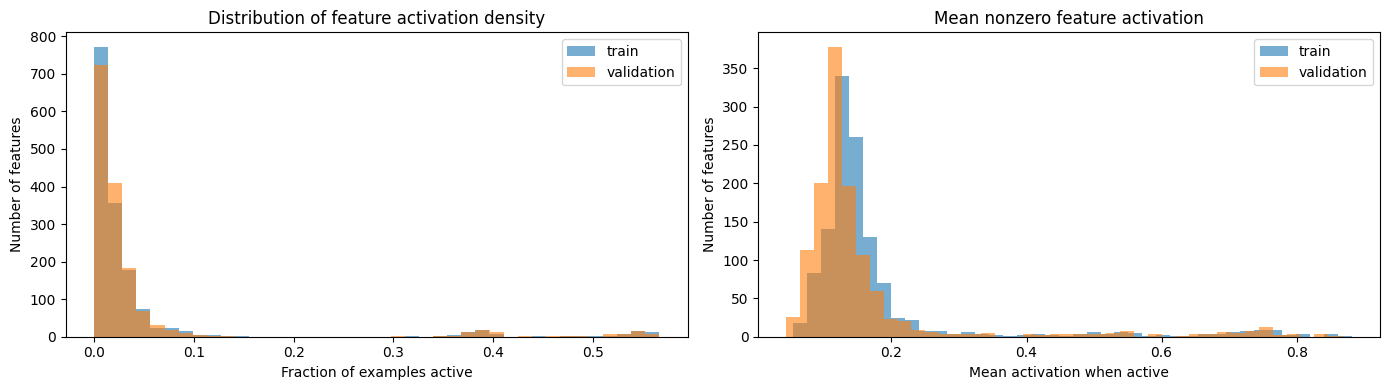

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for split, stats, color_label in [('train', train_stats, 'Training'), ('validation', val_stats, 'Validation')]:
    axes[0].hist(stats['activation_density'], bins=40, alpha=.6, label=split)
    axes[1].hist(stats.loc[stats.active_count>0, 'mean_nonzero_activation'], bins=40, alpha=.6, label=split)
axes[0].set(title='Distribution of feature activation density', xlabel='Fraction of examples active', ylabel='Number of features')
axes[1].set(title='Mean nonzero feature activation', xlabel='Mean activation when active', ylabel='Number of features')
for ax in axes: ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_density_and_strength_distributions.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Feature concentration, rank and activation distributions

TopK guarantees a fixed number of active features per example, but it does not guarantee that all dictionary features are used equally. We inspect concentration in the distribution of total activation mass and identify the most-used features.

The Gini coefficient here describes inequality in aggregate feature activation mass. It is not a measure of interpretability.

{
  "train_feature_mass_gini": 0.8911639502358741,
  "top_10_feature_mass_share": 0.127417653799057,
  "top_20_feature_mass_share": 0.2390211820602417,
  "top_50_feature_mass_share": 0.5543692708015442,
  "top_100_feature_mass_share": 0.8704068660736084
}


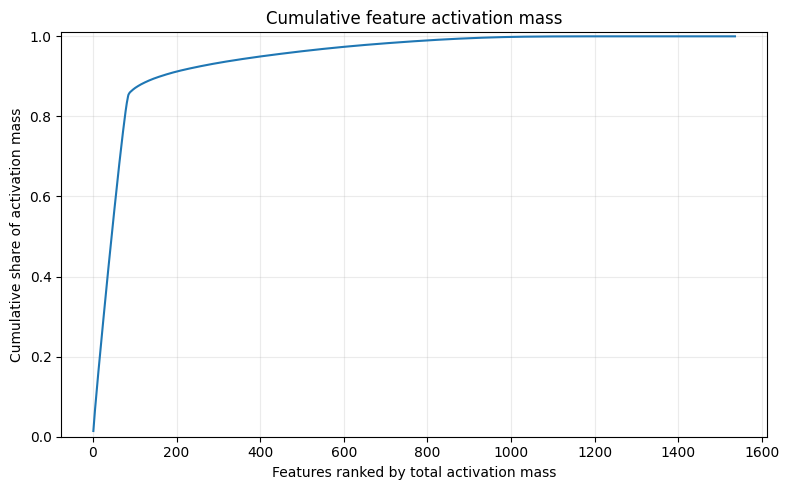

In [ ]:
def gini(x):
    x = np.asarray(x, dtype=float)
    x = np.clip(x, 0, None)
    if x.sum() == 0: return 0.0
    x = np.sort(x)
    n = len(x)
    return float((2*np.sum((np.arange(1,n+1))*x)/(n*x.sum())) - (n+1)/n)

feature_mass = np.abs(train_codes).sum(axis=0)
rank_order = np.argsort(feature_mass)[::-1]
mass_share = feature_mass[rank_order] / max(feature_mass.sum(), 1e-12)
cumulative_share = np.cumsum(mass_share)

concentration = {
    'train_feature_mass_gini': gini(feature_mass),
    'top_10_feature_mass_share': float(mass_share[:10].sum()),
    'top_20_feature_mass_share': float(mass_share[:20].sum()),
    'top_50_feature_mass_share': float(mass_share[:50].sum()),
    'top_100_feature_mass_share': float(mass_share[:100].sum()),
}
print(json.dumps(concentration, indent=2))

rank_df = pd.DataFrame({
    'rank': np.arange(1, DICT_WIDTH+1),
    'feature_id': rank_order,
    'total_absolute_activation': feature_mass[rank_order],
    'activation_mass_share': mass_share,
    'cumulative_mass_share': cumulative_share
})
rank_df.to_csv(TABLE_DIR / 'feature_activation_mass_ranking.csv', index=False)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(rank_df['rank'], rank_df['cumulative_mass_share'])
ax.set(xlabel='Features ranked by total activation mass', ylabel='Cumulative share of activation mass',
       title='Cumulative feature activation mass')
ax.set_ylim(0,1.01)
ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_activation_mass_concentration.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Feature correlations

We calculate correlations between sparse feature-code columns on the Imagenette training split. Because the codes are sparse and many features may be rare, correlations can be unstable for low-support features. We therefore report support counts and focus visualization on features with sufficient support.

This is an exploratory co-activation analysis, not evidence that two features have the same meaning.

Features with adequate support: 991 / 1536


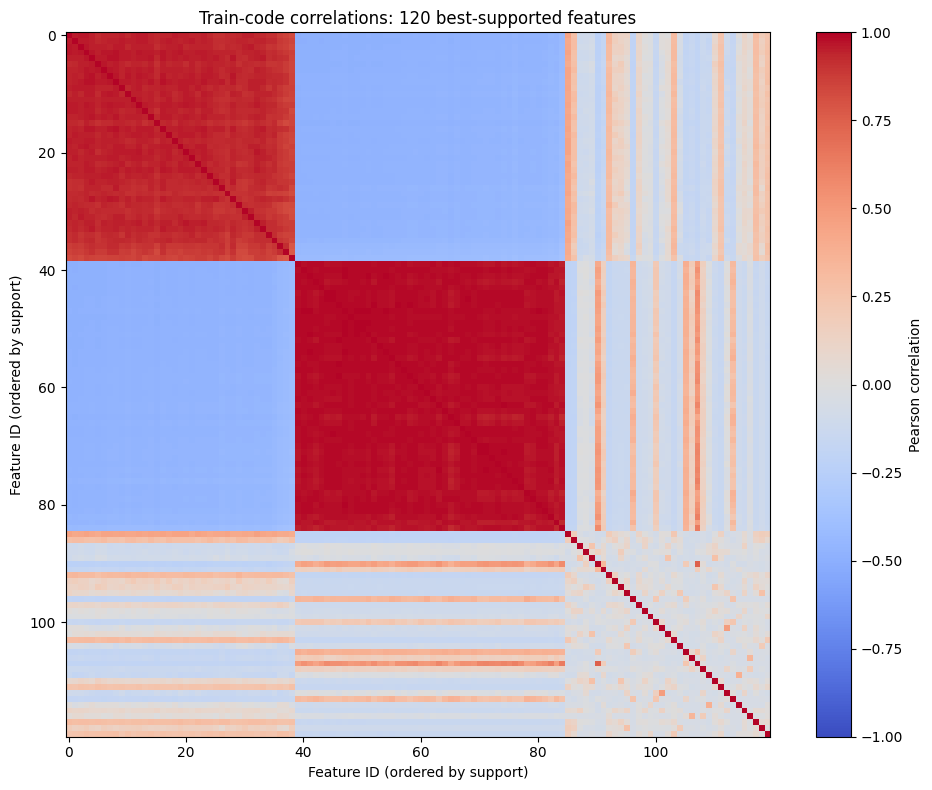

In [ ]:
support = (train_codes != 0).sum(axis=0)
eligible = np.flatnonzero(support >= max(25, int(0.005 * len(train_codes))))
print("Features with adequate support:", len(eligible), "/", DICT_WIDTH)

# Limit the displayed matrix to the 120 most frequently active eligible features.
eligible_ranked = eligible[np.argsort(support[eligible])[::-1]]
corr_features = eligible_ranked[:min(120, len(eligible_ranked))]
corr = np.corrcoef(train_codes[:, corr_features], rowvar=False) if len(corr_features) > 1 else np.zeros((1,1))
corr = np.nan_to_num(corr)

corr_df = pd.DataFrame(corr, index=corr_features, columns=corr_features)
corr_df.to_csv(TABLE_DIR / 'feature_correlation_top_supported.csv')

fig, ax = plt.subplots(figsize=(10,8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm', interpolation='nearest')
ax.set(title=f'Train-code correlations: {len(corr_features)} best-supported features',
       xlabel='Feature ID (ordered by support)', ylabel='Feature ID (ordered by support)')
plt.colorbar(im, ax=ax, label='Pearson correlation')
plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_correlation_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

## 8. Inspect decoder directions

The decoder dictionary contains one 384-D direction per SAE feature. We inspect its norms and pairwise similarity. These are directions in the common observer's pooled activation space; they are not image-space filters and should not be interpreted directly as object labels.

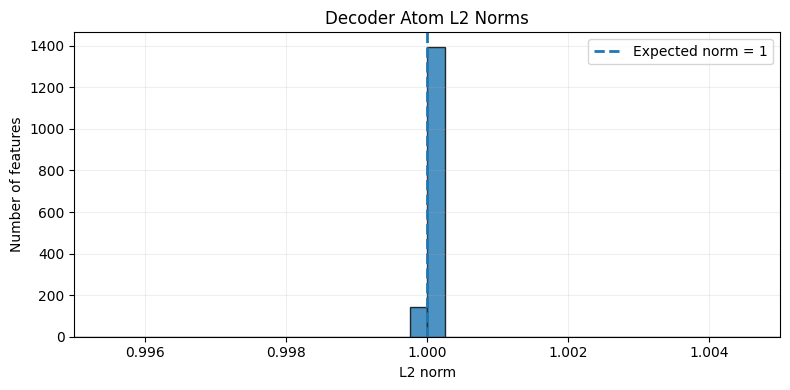

Minimum norm: 0.9999999
Maximum norm: 1.0000001
Mean norm: 1.0


In [ ]:

# ============================================================
# DECODER ATOM L2 NORM — VISUAL CHECK
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    decoder_norms,
    bins=np.linspace(0.995, 1.005, 41),
    edgecolor='black',
    alpha=0.8
)

ax.axvline(
    1.0,
    linestyle='--',
    linewidth=2,
    label='Expected norm = 1'
)

ax.set_xlim(0.995, 1.005)

ax.set(
    title='Decoder Atom L2 Norms',
    xlabel='L2 norm',
    ylabel='Number of features'
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    FIG_DIR / 'decoder_atom_norms.png',
    dpi=180,
    bbox_inches='tight'
)
plt.show()

print("Minimum norm:", decoder_norms.min())
print("Maximum norm:", decoder_norms.max())
print("Mean norm:", decoder_norms.mean())

## 9. Cross-seed dictionary matching

Feature indices are arbitrary across independently trained SAEs. We compare normalized decoder directions using cosine similarity, then use the Hungarian assignment algorithm to obtain a one-to-one best matching.

We report matched cosine similarity and activation-support correspondence. Low matching quality is a meaningful stability result; it should not be hidden by forcing a semantic interpretation.

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize

D1 = normalize(decoder_primary, norm='l2', axis=1)
D2 = normalize(decoder_replicate, norm='l2', axis=1)
similarity = D1 @ D2.T
row_ind, col_ind = linear_sum_assignment(-similarity)
matched_cos = similarity[row_ind, col_ind]

matching = pd.DataFrame({
    'seed123_feature_id': row_ind,
    'seed42_feature_id': col_ind,
    'decoder_cosine_similarity': matched_cos,
    'seed123_train_support': (train_codes != 0).sum(0)[row_ind],
})
matching['seed42_train_support'] = np.nan
matching['seed42_train_support_note'] = 'Computed below on seed-42 encodings'

{
  "matched_features": 1536,
  "mean_cosine_similarity": 0.27682045102119446,
  "median_cosine_similarity": 0.21335488557815552,
  "cosine_q10": 0.1403958797454834,
  "cosine_q90": 0.523485541343689,
  "fraction_cosine_ge_0_8": 0.01171875,
  "fraction_cosine_ge_0_9": 0.0013020833333333333
}


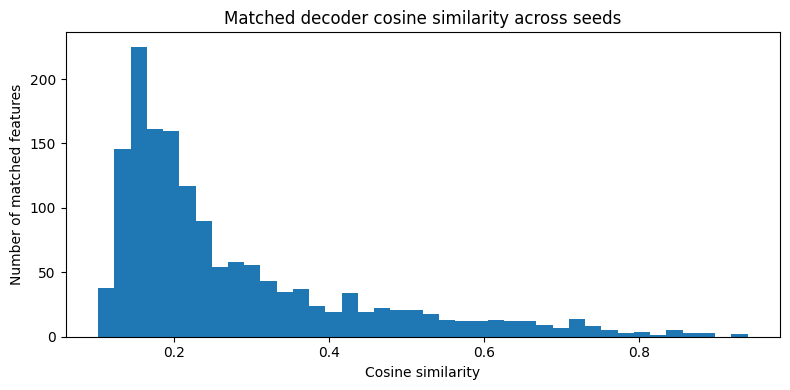

In [ ]:
rep_train_codes, _, _ = encode_array(replicate_model, X_train, return_pre=False)
matching['seed42_train_support'] = (rep_train_codes != 0).sum(0)[col_ind]
matching['support_count_difference'] = (
    matching.seed123_train_support - matching.seed42_train_support
).abs()

matching.to_csv(TABLE_DIR / 'cross_seed_hungarian_feature_matching.csv', index=False)

match_summary = {
    'matched_features': int(len(matching)),
    'mean_cosine_similarity': float(matched_cos.mean()),
    'median_cosine_similarity': float(np.median(matched_cos)),
    'cosine_q10': float(np.quantile(matched_cos, .10)),
    'cosine_q90': float(np.quantile(matched_cos, .90)),
    'fraction_cosine_ge_0_8': float((matched_cos >= .8).mean()),
    'fraction_cosine_ge_0_9': float((matched_cos >= .9).mean())
}
print(json.dumps(match_summary, indent=2))

fig, ax = plt.subplots(figsize=(8,4))
ax.hist(matched_cos, bins=40)
ax.set(title='Matched decoder cosine similarity across seeds',
       xlabel='Cosine similarity', ylabel='Number of matched features')
plt.tight_layout()
plt.savefig(FIG_DIR / 'cross_seed_decoder_similarity.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. Exploratory feature-space embedding

We embed decoder directions into two dimensions using PCA. This is a lightweight, reproducible exploratory view and avoids adding a new UMAP dependency. The plot is not evidence of semantic clusters; it is only a visualization of geometric relationships among decoder vectors.

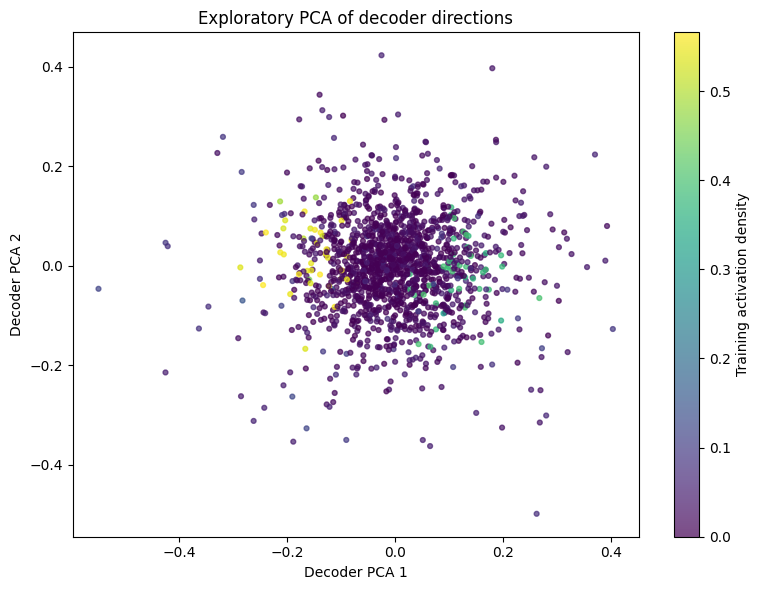

In [ ]:
from sklearn.decomposition import PCA
decoder_2d = PCA(n_components=2, random_state=42).fit_transform(decoder_primary)
fig, ax = plt.subplots(figsize=(8,6))
sc = ax.scatter(decoder_2d[:,0], decoder_2d[:,1],
                c=train_stats.activation_density.values, s=12, alpha=.7, cmap='viridis')
ax.set(title='Exploratory PCA of decoder directions',
       xlabel='Decoder PCA 1', ylabel='Decoder PCA 2')
plt.colorbar(sc, ax=ax, label='Training activation density')
plt.tight_layout()
plt.savefig(FIG_DIR / 'decoder_direction_pca_embedding.png', dpi=180, bbox_inches='tight')
plt.show()

## 11. Natural-image feature galleries

For selected high-use features, rank Imagenette training examples by sparse feature activation and display the original images with their activation values. We use the saved natural-image metadata to resolve image paths. The code inspects metadata columns and fails clearly if a usable path column is not present; it does not guess image identities.

The gallery is an aid to interpretation. Repeated visual patterns may suggest a feature's response preference, but a gallery alone does not establish semantic meaning or causality.

In [ ]:
NATURAL_TRAIN_META = PROJECT_ROOT / 'activations/natural_images/train/metadata.csv'
assert NATURAL_TRAIN_META.exists(), f"Missing natural-image metadata: {NATURAL_TRAIN_META}"
natural_meta = pd.read_csv(NATURAL_TRAIN_META)
print("Natural metadata shape:", natural_meta.shape)
print("Natural metadata columns:", natural_meta.columns.tolist())
display(natural_meta.head())

Natural metadata shape: (9469, 2)
Natural metadata columns: ['sample_index', 'metadata_json']


,sample_index,metadata_json
0,0,"{""split"": ""train"", ""class"": ""n01440764"", ""file..."
1,1,"{""split"": ""train"", ""class"": ""n01440764"", ""file..."
2,2,"{""split"": ""train"", ""class"": ""n01440764"", ""file..."
3,3,"{""split"": ""train"", ""class"": ""n01440764"", ""file..."
4,4,"{""split"": ""train"", ""class"": ""n01440764"", ""file..."


In [ ]:
# ============================================================
# METAMER-SAE — NATURAL IMAGE PATH EXTRACTION
# Extract image paths stored inside metadata_json
# ============================================================

import json
from pathlib import Path

IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.webp'}

def collect_image_paths(obj, prefix=""):
    """
    Recursively extract image-path-like strings from parsed JSON.
    Returns a dictionary mapping JSON field paths to image paths.
    """
    found = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            child_prefix = f"{prefix}.{key}" if prefix else str(key)
            found.update(collect_image_paths(value, child_prefix))

    elif isinstance(obj, list):
        for value in obj:
            found.update(collect_image_paths(value, prefix + "[]"))

    elif isinstance(obj, str):
        if Path(obj.replace("\\", "/")).suffix.lower() in IMAGE_SUFFIXES:
            found[prefix] = obj

    return found


def parse_metadata_json(df):
    parsed_records = []

    for i, value in enumerate(df["metadata_json"]):
        if isinstance(value, dict):
            record = value
        else:
            record = json.loads(str(value))

        if not isinstance(record, dict):
            raise ValueError(
                f"Metadata row {i} did not decode to a JSON dictionary."
            )

        parsed_records.append(record)

    return parsed_records


def resolve_project_path(value, split="train", class_hint=None):
    """
    Resolve metadata paths against the known project and Imagenette
    directory layouts, including paths saved under an older Colab root.
    """

    raw = str(value).strip().replace("\\", "/")
    p = Path(raw)

    natural_root = PROJECT_ROOT / "natural_images"
    dataset_root = natural_root / "imagenette2-320"

    split_dirs = (
        ["train"] if split == "train"
        else ["val", "validation"]
    )

    candidates = []

    # Original path, when still valid
    if p.is_absolute():
        candidates.append(p)

    # Recover paths from older absolute Colab paths
    parts = list(p.parts)

    for marker in ["imagenette2-320", "imagenette2"]:
        if marker in parts:
            idx = parts.index(marker)
            tail = Path(*parts[idx + 1:])
            candidates.append(natural_root / marker / tail)

    if "natural_images" in parts:
        idx = parts.index("natural_images")
        tail = Path(*parts[idx + 1:])
        candidates.append(natural_root / tail)

    # Relative paths
    candidates.extend([
        PROJECT_ROOT / p,
        natural_root / p,
        dataset_root / p,
    ])

    for split_dir in split_dirs:
        candidates.extend([
            dataset_root / split_dir / p,
            natural_root / split_dir / p,
        ])

        # Some metadata records only store the filename.
        if class_hint:
            candidates.extend([
                dataset_root / split_dir / str(class_hint) / p,
                natural_root / split_dir / str(class_hint) / p,
            ])

    for candidate in candidates:
        if candidate.exists() and candidate.is_file():
            return candidate

    return candidates[0]


def extract_metadata_image_paths(df, split="train"):

    records = parse_metadata_json(df)

    # Extract candidate image paths from each JSON record
    row_candidates = [
        collect_image_paths(record) for record in records
    ]

    # Find the JSON field containing image paths in the greatest
    # number of records.
    counts = {}

    for candidates in row_candidates:
        for key in candidates:
            counts[key] = counts.get(key, 0) + 1

    if not counts:
        print("Could not find image paths in metadata_json.")
        print("First decoded metadata record:")
        print(json.dumps(records[0], indent=2))
        raise ValueError("No image-path field found in metadata JSON.")

    def field_preference(key):
        name = key.lower()

        if "thumbnail" in name:
            return 0
        if "image_path" in name or "file_path" in name:
            return 5
        if "filepath" in name or "filename" in name:
            return 4
        if name.endswith("path") or name.endswith("file"):
            return 3
        if "image" in name:
            return 2

        return 1

    selected_key = max(
        counts,
        key=lambda key: (counts[key], field_preference(key))
    )

    print("Detected JSON image-path field:", selected_key)
    print("Records containing this field:", counts[selected_key], "/", len(records))

    if counts[selected_key] != len(records):
        raise ValueError(
            f"Image-path field '{selected_key}' is missing from some "
            "metadata records. Inspect the decoded JSON records."
        )

    raw_paths = [
        candidates[selected_key] for candidates in row_candidates
    ]

    # Extract class names as fallback for filename-only metadata.
    class_hints = []

    for record in records:
        class_hint = record.get("class", None)
        class_hints.append(class_hint)

    resolved_paths = [
        resolve_project_path(path, split, class_hint)
        for path, class_hint in zip(raw_paths, class_hints)
    ]

    missing = [str(p) for p in resolved_paths if not p.exists()]

    print("\nImage path extraction:")
    print("Split:", split)
    print("Total metadata records:", len(records))
    print("Resolved image paths:", len(resolved_paths) - len(missing))
    print("Missing image paths:", len(missing))
    print("Example metadata path:", raw_paths[0])
    print("Example resolved path:", resolved_paths[0])

    if missing:
        print("\nFirst unresolved paths:")
        for path in missing[:5]:
            print(path)

        raise FileNotFoundError(
            "Some image paths could not be resolved. "
            "Check the printed metadata paths and dataset directory."
        )

    return resolved_paths


# Extract Imagenette training image paths
natural_paths = extract_metadata_image_paths(
    natural_meta,
    split="train"
)

assert len(natural_paths) == len(train_codes), (
    f"Path count {len(natural_paths)} does not match "
    f"training code count {len(train_codes)}."
)

print("\nTraining image-path mapping validated.")


Detected JSON image-path field: filename
Records containing this field: 9469 / 9469

Image path extraction:
Split: train
Total metadata records: 9469
Resolved image paths: 9469
Missing image paths: 0
Example metadata path: ILSVRC2012_val_00000293.JPEG
Example resolved path: /content/gdrive/MyDrive/metamer-sae/natural_images/imagenette2-320/train/n01440764/ILSVRC2012_val_00000293.JPEG

Training image-path mapping validated.


In [ ]:
# Select features by training activation mass, excluding dead features.
gallery_feature_ids = rank_order[:12].tolist()
TOP_IMAGES_PER_FEATURE = 8

def make_feature_gallery(feature_id, codes, paths, split_label, output_path):
    scores = codes[:, feature_id]
    top_idx = np.argsort(scores)[::-1]
    top_idx = [i for i in top_idx if scores[i] > 0][:TOP_IMAGES_PER_FEATURE]
    if not top_idx:
        return False
    n = len(top_idx)
    fig, axes = plt.subplots(1, n, figsize=(2.4*n, 3.0))
    if n == 1: axes = [axes]
    for ax, idx in zip(axes, top_idx):
        with Image.open(paths[idx]) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_title(f"#{idx}\n{scores[idx]:.3f}", fontsize=9)
        ax.axis('off')
    fig.suptitle(f"Feature {feature_id} — {split_label} top activations", fontsize=12)
    plt.tight_layout()
    fig.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    return True

gallery_records = []
for fid in gallery_feature_ids:
    out = GALLERY_DIR / f'feature_{fid:04d}_train_top_images.png'
    made = make_feature_gallery(fid, train_codes, natural_paths, 'Imagenette train', out)
    gallery_records.append({'feature_id':fid,'split':'train','gallery_created':made,'path':str(out) if made else ''})

pd.DataFrame(gallery_records).to_csv(TABLE_DIR / 'natural_feature_gallery_index.csv', index=False)
print("Gallery features:", gallery_feature_ids)

Gallery features: [1157, 1323, 751, 988, 881, 821, 1336, 1376, 1187, 1407, 276, 1380]


## 12. Imagenette validation galleries and train/validation feature consistency

Validation examples are kept separate from training galleries. We compare activation density and support across the two natural-image splits. The feature dictionary remains frozen.

In [ ]:
# ============================================================
# VALIDATION IMAGE PATH EXTRACTION
# ============================================================

NATURAL_VAL_META = (
    PROJECT_ROOT / 'activations/natural_images/validation/metadata.csv'
)

assert NATURAL_VAL_META.exists(), (
    f"Missing validation metadata: {NATURAL_VAL_META}"
)

natural_val_meta = pd.read_csv(NATURAL_VAL_META)

print("Validation metadata shape:", natural_val_meta.shape)
print("Validation metadata columns:", natural_val_meta.columns.tolist())

natural_val_paths = extract_metadata_image_paths(
    natural_val_meta,
    split="validation"
)

assert len(natural_val_paths) == len(val_codes)
assert all(p.exists() for p in natural_val_paths)

print("\nValidation image-path mapping validated.")


Validation metadata shape: (3925, 2)
Validation metadata columns: ['sample_index', 'metadata_json']
Detected JSON image-path field: filename
Records containing this field: 3925 / 3925

Image path extraction:
Split: validation
Total metadata records: 3925
Resolved image paths: 3925
Missing image paths: 0
Example metadata path: ILSVRC2012_val_00009111.JPEG
Example resolved path: /content/gdrive/MyDrive/metamer-sae/natural_images/imagenette2-320/val/n01440764/ILSVRC2012_val_00009111.JPEG

Validation image-path mapping validated.


## 13. Load only Feather development activations and pair metadata

This section deliberately reads only the development allocation. We first inspect the manifest and activation metadata, identify the fixed development IDs, and then load only the 8 development triplets. The primary-evaluation and reserve activation arrays are never indexed or analysed here.

The three activation files must preserve their original row ordering and align to their corresponding metadata CSVs.

In [ ]:
STIM_MANIFEST = PROJECT_ROOT / 'stimuli/manifests/stimulus_manifest.csv'
assert STIM_MANIFEST.exists()
stim_manifest = pd.read_csv(STIM_MANIFEST)
print("Stimulus manifest:", stim_manifest.shape)
print("Columns:", stim_manifest.columns.tolist())
display(stim_manifest.head(3))

Stimulus manifest: (48, 45)
Columns: ['stimulus_id', 'source_image_id', 'subset', 'generator_standard_experiment', 'generator_standard_model', 'generator_adversarial_experiment', 'generator_adversarial_model', 'generation_layer', 'random_sampling_seed', 'allocation_method', 'complete_url_triplet', 'source_path', 'standard_metamer_path', 'adversarial_metamer_path', 'source_url', 'standard_metamer_url', 'adversarial_metamer_url', 'retrieval_status', 'all_images_downloaded', 'dimensions_match', 'source_width', 'source_height', 'source_mode', 'source_channels', 'source_format', 'source_file_size_bytes', 'source_sha256', 'source_saved_path', 'standard_width', 'standard_height', 'standard_mode', 'standard_channels', 'standard_format', 'standard_file_size_bytes', 'standard_sha256', 'standard_saved_path', 'adversarial_width', 'adversarial_height', 'adversarial_mode', 'adversarial_channels', 'adversarial_format', 'adversarial_file_size_bytes', 'adversarial_sha256', 'adversarial_saved_path', 're

,stimulus_id,source_image_id,subset,generator_standard_experiment,generator_standard_model,generator_adversarial_experiment,generator_adversarial_model,generation_layer,random_sampling_seed,allocation_method,...,standard_saved_path,adversarial_width,adversarial_height,adversarial_mode,adversarial_channels,adversarial_format,adversarial_file_size_bytes,adversarial_sha256,adversarial_saved_path,retrieval_error_count
0,feather_0000,0,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,116462,a15e076c20b71893c31c92976f044bfe42b887f044c7be...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0
1,feather_0027,27,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,132450,6d1dbb7c75a7c599372f379e289213586b27f8163ec600...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0
2,feather_0084,84,development,experiment_1,resnet50,experiment_3,resnet50_l2_3_robust,layer2_fake_relu,42,seeded_random_without_replacement,...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,224,224,RGB,3,PNG,121547,dd7741f5eb96207788c709f3c5d4930a009c88cc9e149c...,/content/drive/MyDrive/metamer-sae/stimuli/dev...,0


In [ ]:
FEATHER_META_PATHS = {
    'source': PROJECT_ROOT / 'activations/feather/source/metadata.csv',
    'standard': PROJECT_ROOT / 'activations/feather/standard_resnet50/metadata.csv',
    'adversarial': PROJECT_ROOT / 'activations/feather/adversarial_resnet50/metadata.csv'
}
FEATHER_POOL_PATHS = {
    'source': PROJECT_ROOT / 'activations/feather/source/pooled_activations.npy',
    'standard': PROJECT_ROOT / 'activations/feather/standard_resnet50/pooled_activations.npy',
    'adversarial': PROJECT_ROOT / 'activations/feather/adversarial_resnet50/pooled_activations.npy'
}
for p in list(FEATHER_META_PATHS.values()) + list(FEATHER_POOL_PATHS.values()):
    assert p.exists(), f"Missing Feather activation artifact: {p}"

feather_meta = {k: pd.read_csv(v) for k,v in FEATHER_META_PATHS.items()}
for k, df in feather_meta.items():
    print(f"\n{k}: {df.shape}")
    print(df.columns.tolist())
    display(df.head(2))


source: (48, 8)
['sample_index', 'dataset', 'split', 'condition', 'filename', 'relative_path', 'sha256', 'activation_index']


,sample_index,dataset,split,condition,filename,relative_path,sha256,activation_index
0,0,feather,development,source,feather_0000_source.png,stimuli/development/source/feather_0000_source...,1eebae7476f66cb9e68a733135b79fbb5c4a9e20796e54...,0
1,1,feather,development,source,feather_0027_source.png,stimuli/development/source/feather_0027_source...,8a1c9d69e08bb685fa4b8aa51a53287f58e6697c6ec483...,1



standard: (48, 8)
['sample_id', 'dataset', 'split', 'condition', 'filename', 'relative_path', 'sha256', 'activation_index']


,sample_id,dataset,split,condition,filename,relative_path,sha256,activation_index
0,feather_0000,feather,development,standard_resnet50,feather_0000_standard.png,stimuli/development/standard_resnet50/feather_...,d42c4a6521aba61c94f54b7ddb58d0bbe6cde70dca14d2...,0
1,feather_0027,feather,development,standard_resnet50,feather_0027_standard.png,stimuli/development/standard_resnet50/feather_...,e391758da7479486c05213f7e0655d6bc5040312cf6ea3...,1



adversarial: (48, 8)
['sample_id', 'dataset', 'split', 'condition', 'filename', 'relative_path', 'sha256', 'activation_index']


,sample_id,dataset,split,condition,filename,relative_path,sha256,activation_index
0,feather_0000,feather,development,adversarial_resnet50,feather_0000_adversarial.png,stimuli/development/adversarial_resnet50/feath...,a15e076c20b71893c31c92976f044bfe42b887f044c7be...,0
1,feather_0027,feather,development,adversarial_resnet50,feather_0027_adversarial.png,stimuli/development/adversarial_resnet50/feath...,6d1dbb7c75a7c599372f379e289213586b27f8163ec600...,1


In [ ]:
# Identify the manifest's split column and development identifier set.
def find_col(df, candidates):
    lower = {c.lower():c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    return None

split_col = find_col(stim_manifest, ['subset','split','partition','allocation','dataset_split'])
id_col = find_col(stim_manifest, ['stimulus_id','image_id','sample_id','feather_id'])
assert split_col and id_col, (
    f"Cannot identify split/id columns. Manifest columns: {stim_manifest.columns.tolist()}"
)

dev_rows = stim_manifest[stim_manifest[split_col].astype(str).str.lower().str.contains('development|develop|dev', regex=True)].copy()
assert len(dev_rows) == 8, (
    f"Expected exactly 8 development triplets, found {len(dev_rows)}. "
    f"Split values: {stim_manifest[split_col].value_counts(dropna=False).to_dict()}"
)
DEV_IDS = set(dev_rows[id_col].astype(str))
print("Development IDs:", sorted(DEV_IDS))
print("Development triplets:", len(DEV_IDS))

Development IDs: ['feather_0000', 'feather_0027', 'feather_0084', 'feather_0097', 'feather_0119', 'feather_0199', 'feather_0260', 'feather_0308']
Development triplets: 8


In [ ]:
# ============================================================
# METAMER-SAE — FEATHER DEVELOPMENT ACTIVATION ALIGNMENT
# Correctly handles different metadata ID formats.
#
# Source: filename -> stimulus_id
# Standard: sample_id
# Adversarial: sample_id
#
# Uses activation_index to retrieve the correct array rows.
# Only the 8 development triplets are loaded.
# ============================================================

import re
from pathlib import Path

canonical_dev_ids = sorted(DEV_IDS)

assert len(canonical_dev_ids) == 8, (
    f"Expected 8 development IDs, found {len(canonical_dev_ids)}"
)


# ------------------------------------------------------------
# 1. Extract canonical stimulus IDs from each metadata table
# ------------------------------------------------------------

def extract_feather_ids(condition, df):

    if condition == "source":

        filename_col = find_col(
            df,
            ["filename", "file_name"]
        )

        assert filename_col is not None, (
            "Source metadata has no filename column."
        )

        ids = []

        for filename in df[filename_col].astype(str):

            stem = Path(filename).stem

            match = re.fullmatch(
                r"(feather_\d+)_source",
                stem,
                flags=re.IGNORECASE
            )

            assert match is not None, (
                f"Could not extract source stimulus ID from: {filename}"
            )

            ids.append(match.group(1))

    else:

        id_col = find_col(
            df,
            [
                "sample_id",
                "stimulus_id",
                "image_id",
                "feather_id"
            ]
        )

        assert id_col is not None, (
            f"{condition}: Could not identify stimulus ID column. "
            f"Available columns: {df.columns.tolist()}"
        )

        ids = df[id_col].astype(str).str.strip().tolist()

    assert len(ids) == len(df)

    assert len(set(ids)) == len(ids), (
        f"{condition}: Duplicate stimulus IDs found in metadata."
    )

    return ids


# ------------------------------------------------------------
# 2. Identify activation-index columns
# ------------------------------------------------------------

activation_index_cols = {
    condition: find_col(
        df,
        ["activation_index"]
    )
    for condition, df in feather_meta.items()
}

assert all(activation_index_cols.values()), (
    f"Missing activation_index columns: {activation_index_cols}"
)


# ------------------------------------------------------------
# 3. Build stimulus-ID -> activation-index mappings
# ------------------------------------------------------------

metadata_maps = {}

for condition, df in feather_meta.items():

    ids = extract_feather_ids(condition, df)

    index_col = activation_index_cols[condition]

    activation_indices = pd.to_numeric(
        df[index_col],
        errors="raise"
    ).to_numpy()

    assert np.isfinite(activation_indices).all(), (
        f"{condition}: Non-finite activation indices."
    )

    assert np.all(
        activation_indices == np.floor(activation_indices)
    ), (
        f"{condition}: Activation indices must be integers."
    )

    activation_indices = activation_indices.astype(int)

    assert len(set(activation_indices.tolist())) == len(df), (
        f"{condition}: Duplicate activation indices found."
    )

    metadata_maps[condition] = dict(
        zip(ids, activation_indices)
    )

    print(
        f"{condition}: {len(ids)} metadata IDs mapped successfully."
    )


# ------------------------------------------------------------
# 4. Verify all eight development IDs exist in every condition
# ------------------------------------------------------------

dev_indices = {}

for condition, id_to_activation_index in metadata_maps.items():

    missing_ids = [
        sid for sid in canonical_dev_ids
        if sid not in id_to_activation_index
    ]

    assert not missing_ids, (
        f"{condition}: Development IDs missing from metadata: "
        f"{missing_ids}"
    )

    # Crucially, these are activation-array indices,
    # not metadata DataFrame row positions.
    idx = np.asarray(
        [
            id_to_activation_index[sid]
            for sid in canonical_dev_ids
        ],
        dtype=int
    )

    assert idx.shape == (8,)

    dev_indices[condition] = idx


# ------------------------------------------------------------
# 5. Load and validate activation arrays
# ------------------------------------------------------------

feather_dev_raw = {}

for condition, path in FEATHER_POOL_PATHS.items():

    arr = np.load(path, mmap_mode="r")

    assert arr.ndim == 2 and arr.shape[1] == INPUT_DIM, (
        f"{condition}: Unexpected activation shape {arr.shape}"
    )

    df = feather_meta[condition]

    assert len(arr) == len(df), (
        f"{condition}: Activation/metadata count mismatch: "
        f"{len(arr)} activations vs {len(df)} metadata rows."
    )

    # Confirm metadata activation indices cover the array exactly.
    all_indices = np.asarray(
        list(metadata_maps[condition].values()),
        dtype=int
    )

    assert np.array_equal(
        np.sort(all_indices),
        np.arange(len(arr))
    ), (
        f"{condition}: activation_index does not provide a "
        "complete one-to-one mapping to activation rows."
    )

    # Select only the eight development triplets,
    # in the same canonical stimulus-ID order.
    feather_dev_raw[condition] = np.asarray(
        arr[dev_indices[condition]],
        dtype=np.float32
    )

    assert feather_dev_raw[condition].shape == (8, INPUT_DIM)

    assert np.isfinite(feather_dev_raw[condition]).all()

    print(
        f"{condition}: loaded {feather_dev_raw[condition].shape}"
    )


# ------------------------------------------------------------
# 6. Verify exact paired identity across all conditions
# ------------------------------------------------------------

def sorted_id_list(condition):
    """
    Returns stimulus IDs in the exact order used to load
    the development activation arrays.
    """
    return canonical_dev_ids.copy()


assert (
    sorted_id_list("source")
    == sorted_id_list("standard")
    == sorted_id_list("adversarial")
), "Development stimulus alignment failed."


# ------------------------------------------------------------
# 7. Final validation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FEATHER DEVELOPMENT ACTIVATION ALIGNMENT COMPLETE")
print("=" * 65)

print("Development triplets:", len(canonical_dev_ids))
print("Development images:", len(canonical_dev_ids) * 3)

print("\nCanonical development IDs:")
for sid in canonical_dev_ids:
    print(" ", sid)

print("\nActivation shapes:")
for condition, arr in feather_dev_raw.items():
    print(f"  {condition}: {arr.shape}")

print("\nDevelopment-only alignment validated.")
print("Primary evaluation triplets: NOT LOADED")
print("Reserve triplets: NOT LOADED")

source: 48 metadata IDs mapped successfully.
standard: 48 metadata IDs mapped successfully.
adversarial: 48 metadata IDs mapped successfully.
source: loaded (8, 384)
standard: loaded (8, 384)
adversarial: loaded (8, 384)

FEATHER DEVELOPMENT ACTIVATION ALIGNMENT COMPLETE
Development triplets: 8
Development images: 24

Canonical development IDs:
  feather_0000
  feather_0027
  feather_0084
  feather_0097
  feather_0119
  feather_0199
  feather_0260
  feather_0308

Activation shapes:
  source: (8, 384)
  standard: (8, 384)
  adversarial: (8, 384)

Development-only alignment validated.
Primary evaluation triplets: NOT LOADED
Reserve triplets: NOT LOADED


## 14. Encode development stimuli using the frozen primary and replicate SAEs

The saved training mean is subtracted from all three development conditions. The models remain frozen. We calculate feature activations, reconstruction error, active-feature support and source-to-metamer code differences for descriptive development-only inspection.

In [ ]:
feather_dev_centered = {
    k: (v - training_mean[None, :]).astype(np.float32)
    for k,v in feather_dev_raw.items()
}
for k,v in feather_dev_centered.items():
    assert np.isfinite(v).all()
    assert v.shape == (8,384)

dev_codes, dev_recons, dev_metrics = {}, {}, []
for condition, arr in feather_dev_centered.items():
    codes, _, recon = encode_array(primary_model, arr, return_pre=False)
    dev_codes[condition], dev_recons[condition] = codes, recon
    for i in range(len(arr)):
        dev_metrics.append({
            'stimulus_id': sorted_id_list(condition)[i],
            'condition': condition,
            'reconstruction_mse': float(np.mean((arr[i]-recon[i])**2)),
            'active_features': int((codes[i]!=0).sum()),
            'active_feature_count_nonzero': int(np.count_nonzero(codes[i]))
        })

dev_metrics_df = pd.DataFrame(dev_metrics)
dev_metrics_df.to_csv(TABLE_DIR / 'development_feature_encoding_metrics.csv', index=False)
display(dev_metrics_df.groupby('condition').agg(
    n=('stimulus_id','count'),
    mean_reconstruction_mse=('reconstruction_mse','mean'),
    mean_active_features=('active_features','mean')
))

,n,mean_reconstruction_mse,mean_active_features
condition,,,
adversarial,8,0.002767,64.0
source,8,0.002992,64.0
standard,8,0.002952,64.0


In [ ]:
def support_jaccard(a,b):
    sa, sb = set(np.flatnonzero(a)), set(np.flatnonzero(b))
    return len(sa & sb) / max(len(sa | sb), 1)

paired_dev = []
source_codes = dev_codes['source']
for condition in ('standard','adversarial'):
    for i, sid in enumerate(sorted_id_list('source')):
        a, b = source_codes[i], dev_codes[condition][i]
        paired_dev.append({
            'stimulus_id': sid,
            'metamer_condition': condition,
            'source_metamer_code_l2': float(np.linalg.norm(a-b)),
            'source_metamer_code_l1': float(np.abs(a-b).sum()),
            'active_support_jaccard': support_jaccard(a,b),
            'source_active_features': int((a!=0).sum()),
            'metamer_active_features': int((b!=0).sum())
        })

paired_dev_df = pd.DataFrame(paired_dev)
paired_dev_df.to_csv(TABLE_DIR / 'development_source_metamer_feature_differences.csv', index=False)
display(paired_dev_df.groupby('metamer_condition').agg(
    mean_code_l2=('source_metamer_code_l2','mean'),
    mean_code_l1=('source_metamer_code_l1','mean'),
    mean_support_jaccard=('active_support_jaccard','mean')
))

,mean_code_l2,mean_code_l1,mean_support_jaccard
metamer_condition,,,
adversarial,1.593623,11.670372,0.700233
standard,2.996601,22.455610,0.582965


## 15. Which features respond most strongly to each development condition?

For each condition, we rank features by mean activation and activation density across the eight development examples. This is exploratory only: the development set is small and must not be used to select the SAE or tune the primary evaluation.

In [ ]:
dev_feature_rows = []
for condition, codes in dev_codes.items():
    density = (codes != 0).mean(axis=0)
    mean_all = codes.mean(axis=0)
    mean_active = np.divide(codes.sum(axis=0), (codes!=0).sum(axis=0),
                            out=np.zeros(DICT_WIDTH), where=(codes!=0).sum(axis=0)>0)
    for fid in range(DICT_WIDTH):
        dev_feature_rows.append({
            'condition': condition,
            'feature_id': fid,
            'activation_density': density[fid],
            'mean_activation_all': mean_all[fid],
            'mean_activation_when_active': mean_active[fid]
        })

dev_feature_stats = pd.DataFrame(dev_feature_rows)
dev_feature_stats.to_csv(TABLE_DIR / 'development_condition_feature_statistics.csv', index=False)

top_dev = (dev_feature_stats.sort_values(['condition','mean_activation_all'], ascending=[True,False])
           .groupby('condition').head(20))
display(top_dev)

,condition,feature_id,activation_density,mean_activation_all,mean_activation_when_active
4060,adversarial,988,0.625,0.702599,1.124159
4408,adversarial,1336,0.625,0.592291,0.947665
4395,adversarial,1323,0.625,0.578381,0.925409
3823,adversarial,751,0.625,0.571340,0.914144
4229,adversarial,1157,0.625,0.570449,0.912719
3674,adversarial,602,0.625,0.553951,0.886322
4448,adversarial,1376,0.625,0.522205,0.835527
3108,adversarial,36,0.625,0.521565,0.834505
3255,adversarial,183,0.625,0.500045,0.800073
3742,adversarial,670,0.625,0.492675,0.788280


,condition_a,condition_b,top20_intersection,top20_jaccard
0,source,standard,5,0.142857
1,source,adversarial,5,0.142857
2,standard,adversarial,18,0.818182


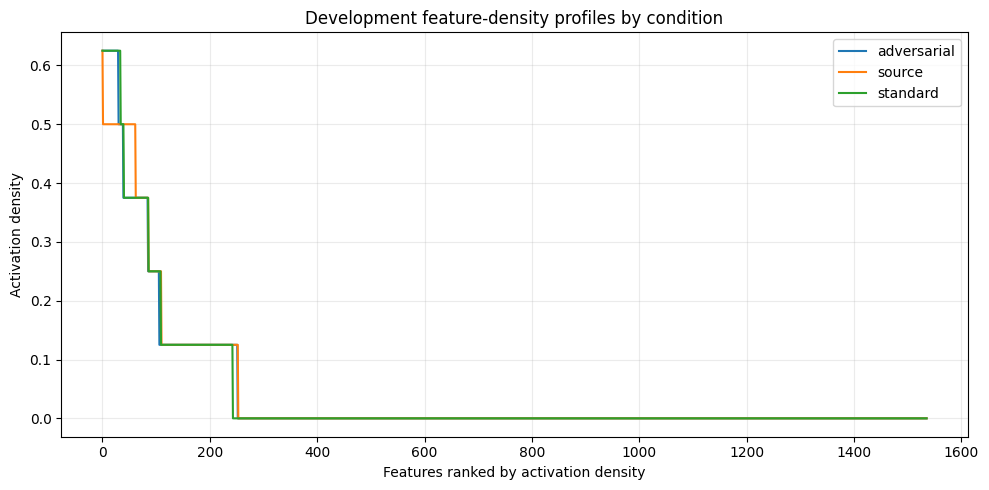

In [ ]:
top_ids_by_condition = {
    c: set(df.nlargest(20, 'mean_activation_all').feature_id)
    for c, df in dev_feature_stats.groupby('condition')
}
overlap_rows = []
for a,b in [('source','standard'),('source','adversarial'),('standard','adversarial')]:
    A, B = top_ids_by_condition[a], top_ids_by_condition[b]
    overlap_rows.append({'condition_a':a,'condition_b':b,'top20_intersection':len(A&B),
                         'top20_jaccard':len(A&B)/max(len(A|B),1)})
top_overlap_df = pd.DataFrame(overlap_rows)
display(top_overlap_df)
top_overlap_df.to_csv(TABLE_DIR / 'development_top_feature_overlap.csv', index=False)

fig, ax = plt.subplots(figsize=(10,5))
for condition, df in dev_feature_stats.groupby('condition'):
    ax.plot(np.sort(df.activation_density.values)[::-1], label=condition)
ax.set(title='Development feature-density profiles by condition',
       xlabel='Features ranked by activation density', ylabel='Activation density')
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.savefig(FIG_DIR / 'development_feature_density_profiles.png', dpi=180, bbox_inches='tight')
plt.show()

## 16. Development stimulus feature-response heatmap

We visualize the strongest features across the 24 development images. Each column is a stimulus; each row is a feature. The feature set is selected by total response across development images for visualization only. The plot is not a held-out result.

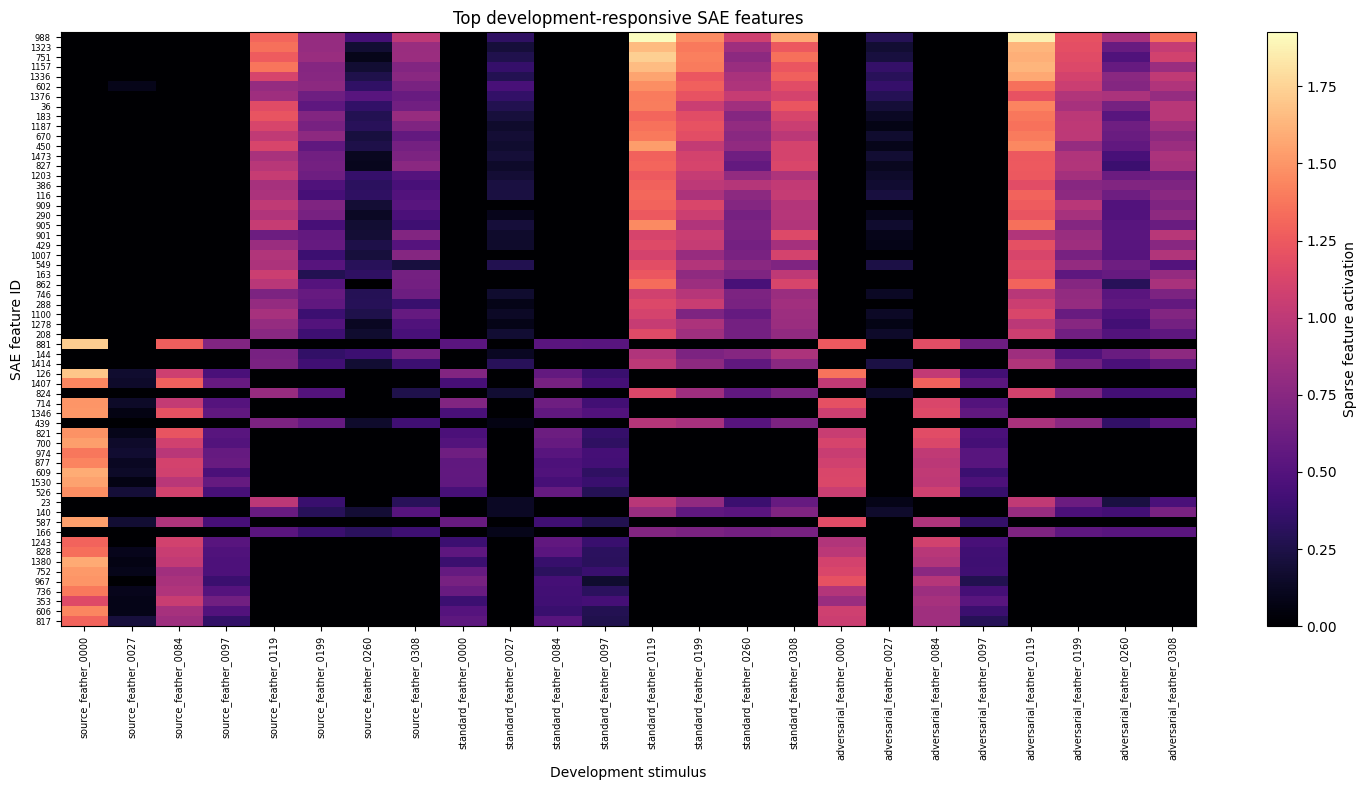

In [ ]:
condition_order = ['source','standard','adversarial']
dev_matrix = np.concatenate([dev_codes[c] for c in condition_order], axis=0)
dev_labels = [f'{c}_{sid}' for c in condition_order for sid in sorted_id_list(c)]
selected_dev_features = np.argsort(dev_matrix.mean(axis=0))[::-1][:60]
heat = dev_matrix[:, selected_dev_features].T

fig, ax = plt.subplots(figsize=(15,8))
im = ax.imshow(heat, aspect='auto', interpolation='nearest', cmap='magma')
ax.set_yticks(np.arange(len(selected_dev_features)))
ax.set_yticklabels(selected_dev_features, fontsize=6)
ax.set_xticks(np.arange(len(dev_labels)))
ax.set_xticklabels(dev_labels, rotation=90, fontsize=7)
ax.set(title='Top development-responsive SAE features',
       xlabel='Development stimulus', ylabel='SAE feature ID')
plt.colorbar(im, ax=ax, label='Sparse feature activation')
plt.tight_layout()
plt.savefig(FIG_DIR / 'development_feature_response_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()

## 17. Seed-42 replicate: development response robustness

We encode the same permitted natural and development activations using the seed-42 replicate. Feature IDs are not directly comparable across seeds. We use the decoder-based Hungarian mapping computed above to align seed-42 features to their seed-123 counterparts before comparing responses.

In [ ]:
dev_codes_seed42 = {}
for condition, arr in feather_dev_centered.items():
    c, _, _ = encode_array(replicate_model, arr, return_pre=False)
    dev_codes_seed42[condition] = c

# Mapping: seed123 feature -> matched seed42 feature
seed42_for_seed123 = dict(zip(matching.seed123_feature_id, matching.seed42_feature_id))

stability_rows = []
for condition in condition_order:
    c123 = dev_codes[condition]
    c42 = dev_codes_seed42[condition]
    matched_42 = np.zeros_like(c123)
    for f123, f42 in seed42_for_seed123.items():
        matched_42[:, int(f123)] = c42[:, int(f42)]
    # Compare aligned activation profiles, including zeros.
    for f in range(DICT_WIDTH):
        x, y = c123[:,f], matched_42[:,f]
        denom = np.linalg.norm(x)*np.linalg.norm(y)
        cos = float(np.dot(x,y)/denom) if denom > 0 else np.nan
        stability_rows.append({
            'condition':condition,'seed123_feature_id':f,
            'matched_seed42_feature_id':int(seed42_for_seed123[f]),
            'decoder_cosine':float(similarity[f, int(seed42_for_seed123[f])]),
            'development_response_cosine':cos,
            'seed123_mean_response':float(x.mean()),
            'seed42_matched_mean_response':float(y.mean())
        })

dev_seed_stability = pd.DataFrame(stability_rows)
dev_seed_stability.to_csv(TABLE_DIR / 'development_cross_seed_response_stability.csv', index=False)
display(dev_seed_stability.groupby('condition').agg(
    mean_decoder_cosine=('decoder_cosine','mean'),
    median_decoder_cosine=('decoder_cosine','median'),
    mean_response_cosine=('development_response_cosine','mean')
))

,mean_decoder_cosine,median_decoder_cosine,mean_response_cosine
condition,,,
adversarial,0.27682,0.213355,0.754037
source,0.27682,0.213355,0.727923
standard,0.27682,0.213355,0.677719


## 18. Optional feature-gallery index for development stimuli

This section creates a concise table of which development images most strongly activate selected natural-image features. It does not use image attribution or spatial heatmaps: this SAE is pooled, so its codes have no spatial coordinates.

In [ ]:
dev_gallery_features = rank_order[:20]
dev_gallery_rows = []
for condition in condition_order:
    codes = dev_codes[condition]
    for fid in dev_gallery_features:
        order = np.argsort(codes[:,fid])[::-1]
        for rank, idx in enumerate(order[:8], start=1):
            dev_gallery_rows.append({
                'condition':condition,
                'feature_id':int(fid),
                'rank':rank,
                'stimulus_id':sorted_id_list(condition)[idx],
                'activation':float(codes[idx,fid])
            })
dev_gallery_index = pd.DataFrame(dev_gallery_rows)
dev_gallery_index.to_csv(TABLE_DIR / 'development_feature_gallery_index.csv', index=False)
display(dev_gallery_index.head(30))

,condition,feature_id,rank,stimulus_id,activation
0,source,1157,1,feather_0119,1.373521
1,source,1157,2,feather_0199,0.741003
2,source,1157,3,feather_0308,0.722915
3,source,1157,4,feather_0260,0.181059
4,source,1157,5,feather_0097,0.000000
5,source,1157,6,feather_0084,0.000000
6,source,1157,7,feather_0027,0.000000
7,source,1157,8,feather_0000,0.000000
8,source,1323,1,feather_0119,1.350888
9,source,1323,2,feather_0308,0.833929


## 19. Consolidated analysis figures and tables

The following outputs are written under `outputs/topk_feature_analysis/`. They are reproducible analysis artifacts; no original training artifacts are modified.

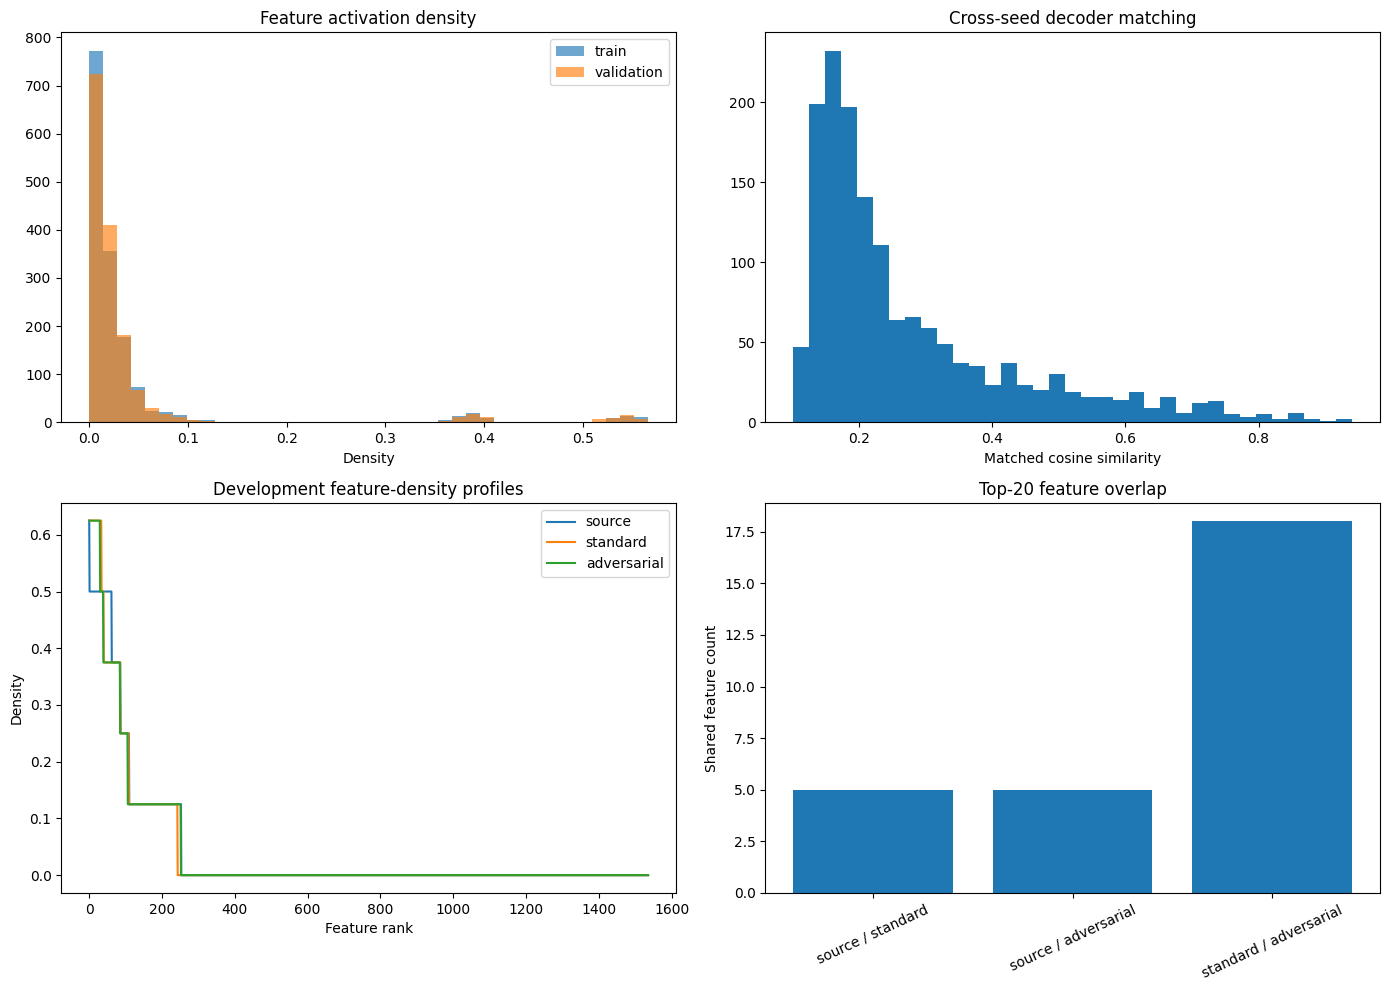

In [ ]:
# Compact overview figure for Notebook 07.
fig, axes = plt.subplots(2,2, figsize=(14,10))

axes[0,0].hist(train_stats.activation_density, bins=40, alpha=.65, label='train')
axes[0,0].hist(val_stats.activation_density, bins=40, alpha=.65, label='validation')
axes[0,0].set_title('Feature activation density')
axes[0,0].set_xlabel('Density'); axes[0,0].legend()

axes[0,1].hist(matched_cos, bins=35)
axes[0,1].set_title('Cross-seed decoder matching')
axes[0,1].set_xlabel('Matched cosine similarity')

for condition in condition_order:
    axes[1,0].plot(np.sort(dev_feature_stats.query('condition == @condition').activation_density)[::-1],
                   label=condition)
axes[1,0].set_title('Development feature-density profiles')
axes[1,0].set_xlabel('Feature rank'); axes[1,0].set_ylabel('Density'); axes[1,0].legend()

axes[1,1].bar(top_overlap_df.condition_a + ' / ' + top_overlap_df.condition_b,
              top_overlap_df.top20_intersection)
axes[1,1].set_title('Top-20 feature overlap')
axes[1,1].set_ylabel('Shared feature count')
axes[1,1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(FIG_DIR / 'notebook_07_summary_dashboard.png', dpi=180, bbox_inches='tight')
plt.show()

## 20. Save provenance and closure report

The report records the selected checkpoints, preprocessing, data partitions, output locations and key summary measurements. It explicitly states that the 32 primary and 8 reserve triplets were not analysed.

In [ ]:
closure = {
    'notebook': '07_topk_feature_analysis.ipynb',
    'project': 'metamer-sae',
    'created_utc': pd.Timestamp.utcnow().isoformat(),
    'status': 'analysis_executed_pending_output_review',
    'primary_checkpoint': str(PRIMARY_CKPT),
    'replicate_checkpoint': str(REPLICATE_CKPT),
    'primary_seed': 123,
    'replicate_seed': 42,
    'architecture': {'input_dim':384,'dictionary_width':1536,'top_k':64,'expansion':4},
    'preprocessing': 'subtract saved Imagenette training activation mean only; no scaling or whitening',
    'natural_data': {'train_n':int(len(X_train)),'validation_n':int(len(X_val))},
    'feather_data_used': {'development_triplets':8,'development_images':24,
                          'primary_evaluation_triplets_used':0,'reserve_triplets_used':0},
    'human_behavioral_data_used': False,
    'spatial_sae_used': False,
    'natural_reconstruction_mse': natural_reconstruction.to_dict(orient='records'),
    'feature_utilization': summary.to_dict(orient='records'),
    'train_validation_support_jaccard': support_jaccard,
    'cross_seed_matching': match_summary,
    'development_condition_metrics': dev_metrics_df.groupby('condition').reconstruction_mse.mean().to_dict(),
    'outputs': {
        'figures': str(FIG_DIR),
        'tables': str(TABLE_DIR),
        'natural_feature_galleries': str(GALLERY_DIR)
    },
    'interpretation_cautions': [
        'Feature galleries are descriptive and do not prove semantic meaning.',
        'Decoder matching is approximate; report the matching distribution.',
        'Development triplets are exploratory only.',
        'No causal claims are made from activation patterns.',
        'No human recognisability inference is made.'
    ]
}

with open(OUTPUT_DIR / 'notebook_07_closure_report.json', 'w') as f:
    json.dump(closure, f, indent=2, default=str)

with open(OUTPUT_DIR / 'notebook_07_run_config.json', 'w') as f:
    json.dump({
        'primary_checkpoint': str(PRIMARY_CKPT),
        'replicate_checkpoint': str(REPLICATE_CKPT),
        'input_dim': INPUT_DIM, 'dictionary_width': DICT_WIDTH, 'top_k': TOP_K,
        'device': str(DEVICE), 'natural_train_n':len(X_train), 'natural_validation_n':len(X_val),
        'feather_subset':'development_only', 'development_triplets':8,
        'primary_and_reserve_loaded':False
    }, f, indent=2)

print("Saved closure report:", OUTPUT_DIR / 'notebook_07_closure_report.json')
print("Saved run config:", OUTPUT_DIR / 'notebook_07_run_config.json')

Saved closure report: /content/gdrive/MyDrive/metamer-sae/outputs/topk_feature_analysis/notebook_07_closure_report.json
Saved run config: /content/gdrive/MyDrive/metamer-sae/outputs/topk_feature_analysis/notebook_07_run_config.json


## 21. Notebook 07 completion checklist

Notebook 07 is not considered complete merely because the cells execute. Review the generated tables, galleries and figures, then update the closure report's status after inspecting the outputs.

- [ ] Both selected checkpoints load with `weights_only=True` and strict state-dictionary matching.
- [ ] Model output dimensions and TopK=64 sparsity checks pass.
- [ ] Saved training mean is used without refitting or extra scaling.
- [ ] Natural train and validation feature statistics are saved separately.
- [ ] Feature density, dead-feature, activation-strength and correlation analyses are reviewed.
- [ ] Natural-image galleries show valid images and correctly ranked activations.
- [ ] Cross-seed decoder matching distribution is reviewed; raw indices are not treated as aligned.
- [ ] Only the eight Feather development triplets are used.
- [ ] Source/standard/adversarial development feature-response summaries are reviewed.
- [ ] No primary or reserve triplets were loaded or analysed.
- [ ] No human behavioural data were loaded.
- [ ] Figures, CSV tables, configuration and closure report are saved.
- [ ] Any unexpected metadata/path issues are resolved and documented.
- [ ] Final interpretations distinguish descriptive association from semantic or causal claims.

### Expected output structure

```text
outputs/topk_feature_analysis/
├── figures/
├── tables/
├── feature_galleries/
├── notebook_07_run_config.json
└── notebook_07_closure_report.json
```

### What comes next

After Notebook 07 outputs have been inspected and the feature-analysis decisions are frozen, proceed to **Notebook 08 — Paired metamer evaluation**. Notebook 08 will first debug on the eight development triplets, then evaluate the 32 held-out primary triplets. The eight reserve triplets remain withheld.

Human-recognition analysis remains a later, separately initiated experiment. The full `metamer-sae` codebase remains the expanded implementation built from the validated Colab prototype.